# Imports & Config

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import json
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from scipy import stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
import gc

DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_ROOT = Path('/content/drive/MyDrive/uav_thesis/processed_10hz/v2')
MODEL_ROOT  = Path('/content/drive/MyDrive/uav_thesis/model_outputs/v2')
AE_DIR      = MODEL_ROOT / '05_ae_comparison'
OUT_DIR     = MODEL_ROOT / 'v3b/07_anomaly_enriched'
OUT_DIR.mkdir(parents=True, exist_ok=True)

FOLDS  = [f'fold_{i:02d}' for i in range(1, 6)]
TARGET = 'target_energy_next_60s_wh'
WINDOW = 100
STRIDE = 10
BATCH  = 256
INNER_FOLDS    = 4
INNER_AE_DIR   = MODEL_ROOT / 'v3b/07b_inner_ae_weights'
ENRICHED_DIR   = MODEL_ROOT / 'v3b/07_enriched_parquets_windowlevel'
OUT_DIR.mkdir(parents=True, exist_ok=True)
INNER_AE_DIR.mkdir(parents=True, exist_ok=True)
ENRICHED_DIR.mkdir(parents=True, exist_ok=True)

print(f'Device: {DEVICE}')
print(f'Output: {OUT_DIR}')

Device: cuda
Output: /content/drive/MyDrive/uav_thesis/model_outputs/v2/v3b/07_anomaly_enriched


# Transformer-AE Architecture

In [20]:
class TransformerAutoencoder(nn.Module):
    def __init__(self, n_features, d_model=64, nhead=4, num_layers=2,
                 dropout=0.1, dim_feedforward=256, max_seq_len=200):
        super().__init__()
        self.input_proj   = nn.Linear(n_features, d_model)
        self.pos_encoding = nn.Parameter(
            torch.randn(1, max_seq_len, d_model) * 0.02
        )
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout, batch_first=True, norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer,
                                                  num_layers=num_layers,
                                                  enable_nested_tensor=False)
        self.output_proj = nn.Linear(d_model, n_features)

    def forward(self, x):
        seq_len = x.size(1)
        x = self.input_proj(x) + self.pos_encoding[:, :seq_len, :]
        x = self.transformer(x)
        return self.output_proj(x)


def score_split(df_split, model, feature_cols, threshold, flight_col='log_id'):
    """
    Window a scaled split dataframe, compute per-window MSE,
    aggregate to flight-level mean score.
    Returns a dataframe with one row per flight.
    """
    model.eval()
    flight_scores = {}

    for flight_id, grp in df_split.groupby(flight_col):
        X = grp[feature_cols].values.astype(np.float32)
        n = len(X)
        windows = []
        for start in range(0, n - WINDOW + 1, STRIDE):
            windows.append(X[start:start + WINDOW])
        if not windows:                          # flight shorter than window
            windows.append(X[:n])               # use full flight as one window

        windows_t = torch.tensor(np.stack(windows), dtype=torch.float32).to(DEVICE)
        with torch.no_grad():
            recon = model(windows_t)
        mse_per_window = ((windows_t - recon) ** 2).mean(dim=(1, 2)).cpu().numpy()
        flight_scores[flight_id] = float(mse_per_window.mean())

    scores_df = pd.DataFrame(
        list(flight_scores.items()), columns=[flight_col, 'anomaly_score']
    )
    scores_df['anomaly_flag'] = (scores_df['anomaly_score'] > threshold).astype(int)
    return scores_df

In [21]:
def score_split_windowlevel(df_split, model, feature_cols, threshold, flight_col='log_id'):
    """
    Assigns each row the MSE of the window whose centre is closest to that row.
    Returns df_split with 'anomaly_score' and 'anomaly_flag' columns added.
    """
    model.eval()
    result_frames = []

    for flight_id, grp in df_split.groupby(flight_col):
        grp = grp.copy().reset_index(drop=True)
        X = grp[feature_cols].values.astype(np.float32)
        n = len(X)

        windows, centres = [], []
        for start in range(0, n - WINDOW + 1, STRIDE):
            windows.append(X[start:start + WINDOW])
            centres.append(start + WINDOW // 2)

        if not windows:
            windows.append(X[:n])
            centres.append(n // 2)

        windows_t = torch.tensor(np.stack(windows), dtype=torch.float32).to(DEVICE)
        with torch.no_grad():
            recon = model(windows_t)
        mse_per_window = ((windows_t - recon) ** 2).mean(dim=(1, 2)).cpu().numpy()

        centres = np.array(centres)
        row_scores = np.array([
            mse_per_window[np.argmin(np.abs(centres - i))]
            for i in range(n)
        ])

        grp['anomaly_score'] = row_scores
        grp['anomaly_flag']  = (row_scores > threshold).astype(int)
        result_frames.append(grp)

    return pd.concat(result_frames, ignore_index=True)

# Generate OOF + Test Scores for All Folds

In [22]:
def make_windows_from_df(df, feature_cols, window=100, stride=10):
    windows, flight_ids = [], []
    for fid, grp in df.groupby('log_id'):
        X = grp[feature_cols].values.astype(np.float32)
        if len(X) < window:
            pad = np.zeros((window - len(X), X.shape[1]), dtype=np.float32)
            X = np.concatenate([X, pad], axis=0)
            windows.append(X)
            flight_ids.append(fid)
        else:
            for start in range(0, len(X) - window + 1, stride):
                windows.append(X[start:start+window])
                flight_ids.append(fid)
    return np.stack(windows).astype(np.float32), flight_ids

def train_inner_ae(model, X_tr, X_va, epochs=100, patience=10, batch=256):
    from torch.utils.data import DataLoader, TensorDataset
    opt     = torch.optim.Adam(model.parameters(), lr=1e-4)
    loss_fn = nn.MSELoss()
    tr_dl   = DataLoader(TensorDataset(torch.tensor(X_tr)),
                         batch_size=batch, shuffle=True)
    X_va_t  = torch.tensor(X_va).to(DEVICE)
    best_val, ctr, best_state = np.inf, 0, None
    for epoch in range(epochs):
        model.train()
        for (xb,) in tr_dl:
            xb = xb.to(DEVICE)
            opt.zero_grad()
            loss_fn(model(xb), xb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            vl = loss_fn(model(X_va_t), X_va_t).item()
        if vl < best_val:
            best_val   = vl
            best_state = {k: v.cpu().clone() for k,v in model.state_dict().items()}
            ctr = 0
        else:
            ctr += 1
            if ctr >= patience:
                break
    model.load_state_dict(best_state)
    return model

def score_df_flights_windowlevel(df, model, feature_cols):
    model.eval()
    row_scores = {}
    for fid, grp in df.groupby('log_id'):
        grp = grp.reset_index(drop=True)
        X = grp[feature_cols].values.astype(np.float32)
        n = len(X)
        wins, centres = [], []
        for start in range(0, n - WINDOW + 1, STRIDE):
            wins.append(X[start:start + WINDOW])
            centres.append(start + WINDOW // 2)
        if not wins:
            wins.append(X)
            centres.append(n // 2)
        wt = torch.tensor(np.array(wins, dtype=np.float32)).to(DEVICE)
        with torch.no_grad():
            recon = model(wt)
        mse = ((wt - recon) ** 2).mean(dim=(1, 2)).cpu().numpy()
        centres = np.array(centres)
        row_scores[fid] = np.array([
            mse[np.argmin(np.abs(centres - i))]
            for i in range(n)
        ])
    return row_scores

In [23]:
state = torch.load(AE_DIR / 'transformer_ae_fold_01.pt', map_location='cpu')
for k in state.keys():
    print(k)

pos_encoding
input_proj.weight
input_proj.bias
transformer.layers.0.self_attn.in_proj_weight
transformer.layers.0.self_attn.in_proj_bias
transformer.layers.0.self_attn.out_proj.weight
transformer.layers.0.self_attn.out_proj.bias
transformer.layers.0.linear1.weight
transformer.layers.0.linear1.bias
transformer.layers.0.linear2.weight
transformer.layers.0.linear2.bias
transformer.layers.0.norm1.weight
transformer.layers.0.norm1.bias
transformer.layers.0.norm2.weight
transformer.layers.0.norm2.bias
transformer.layers.1.self_attn.in_proj_weight
transformer.layers.1.self_attn.in_proj_bias
transformer.layers.1.self_attn.out_proj.weight
transformer.layers.1.self_attn.out_proj.bias
transformer.layers.1.linear1.weight
transformer.layers.1.linear1.bias
transformer.layers.1.linear2.weight
transformer.layers.1.linear2.bias
transformer.layers.1.norm1.weight
transformer.layers.1.norm1.bias
transformer.layers.1.norm2.weight
transformer.layers.1.norm2.bias
output_proj.weight
output_proj.bias


In [24]:
all_scores = []   # flight-level scores across all folds

for fold in FOLDS:
    print(f'\n── {fold} ──')
    fold_dir = OUTPUT_ROOT / fold
    suffix   = f'v5_voltage_kfold5_{fold}'

    # Load scaled parquets
    df_train = pd.read_parquet(fold_dir / f'train_no_dr_scaled_{suffix}.parquet')
    df_val   = pd.read_parquet(fold_dir / f'val_no_dr_scaled_{suffix}.parquet')
    df_test  = pd.read_parquet(fold_dir / f'test_no_dr_scaled_{suffix}.parquet')

    # Load feature cols
    with open(fold_dir / f'feature_cols_{fold}.json') as f:
        feature_cols = json.load(f)
    n_features = len(feature_cols)
    print(f'  Features: {n_features}')

    # Compute threshold from normal training flights
    # (p95 of per-flight mean reconstruction error on normal-labelled train rows)
    model = TransformerAutoencoder(n_features=n_features).to(DEVICE)
    wt_path = AE_DIR / f'transformer_ae_{fold}.pt'
    model.load_state_dict(torch.load(wt_path, map_location=DEVICE))
    model.eval()
    print(f'  Loaded weights: {wt_path.name}')

    # Threshold: p95 on normal train flights
    NOT_SUSPICIOUS = df_train['voltage_per_cell_suspicious'].min()
    normal_train = df_train[
        (df_train['dataset_label'] == 'normal') &
        (df_train['voltage_per_cell_suspicious'] == NOT_SUSPICIOUS)
    ]
    print(f'  Normal clean rows: {len(normal_train)} | flights: {normal_train["log_id"].nunique()}')
    train_scores = score_split(normal_train, model, feature_cols, threshold=0.0)
    threshold = np.percentile(train_scores['anomaly_score'].values, 95)
    print(f'  Threshold (p95 normal train): {threshold:.6f}')

    # Score val (OOF) and test — window-level
    val_scores  = score_split_windowlevel(df_val,  model, feature_cols, threshold)
    test_scores = score_split_windowlevel(df_test, model, feature_cols, threshold)

    # Carry over metadata
    for scored_df, split_name in [
        (val_scores,  'val'),
        (test_scores, 'test'),
    ]:
        scored_df['split']     = split_name
        scored_df['fold']      = fold
        scored_df['threshold'] = threshold

    all_scores.append(val_scores)
    all_scores.append(test_scores)
    print(f'  Val rows scored : {len(val_scores)}')
    print(f'  Test rows scored: {len(test_scores)}')

df_all_scores = pd.concat(all_scores, ignore_index=True)
df_all_scores.to_parquet(OUT_DIR / 'oof_and_test_anomaly_scores_windowlevel.parquet', index=False)
print(f'\nTotal row scores saved: {len(df_all_scores)}')
print(df_all_scores.groupby(['fold', 'split']).size().unstack())


── fold_01 ──
  Features: 16
  Loaded weights: transformer_ae_fold_01.pt
  Normal clean rows: 395382 | flights: 83
  Threshold (p95 normal train): 0.000002
  Val rows scored : 110878
  Test rows scored: 190831

── fold_02 ──
  Features: 16
  Loaded weights: transformer_ae_fold_02.pt
  Normal clean rows: 400917 | flights: 84
  Threshold (p95 normal train): 0.000002
  Val rows scored : 105335
  Test rows scored: 218552

── fold_03 ──
  Features: 16
  Loaded weights: transformer_ae_fold_03.pt
  Normal clean rows: 402551 | flights: 82
  Threshold (p95 normal train): 0.000002
  Val rows scored : 105412
  Test rows scored: 183560

── fold_04 ──
  Features: 16
  Loaded weights: transformer_ae_fold_04.pt
  Normal clean rows: 409525 | flights: 83
  Threshold (p95 normal train): 0.000011
  Val rows scored : 114458
  Test rows scored: 181286

── fold_05 ──
  Features: 16
  Loaded weights: transformer_ae_fold_05.pt
  Normal clean rows: 380945 | flights: 82
  Threshold (p95 normal train): 0.000001

# OOF scores for train rows

In [25]:
all_train_oof = []

for fold in FOLDS:
    out_path = OUT_DIR / f'train_oof_scores_windowlevel_{fold}.parquet'
    if out_path.exists():
        print(f'{fold} — checkpoint found, loading')
        all_train_oof.append(pd.read_parquet(out_path))
        continue

    print(f'\n{"="*60}\nOuter fold: {fold}\n{"="*60}')
    fold_dir = OUTPUT_ROOT / fold
    suffix   = f'v5_voltage_kfold5_{fold}'

    with open(fold_dir / f'feature_cols_{fold}.json') as f:
        feature_cols = json.load(f)
    n_features = len(feature_cols)

    df_train = pd.read_parquet(
        fold_dir / f'train_no_dr_scaled_{suffix}.parquet')

    NOT_SUSPICIOUS = df_train['voltage_per_cell_suspicious'].min()
    df_normal = df_train[
        (df_train['dataset_label'] == 'normal') &
        (df_train['voltage_per_cell_suspicious'] == NOT_SUSPICIOUS)
    ]
    normal_ids    = df_normal['log_id'].unique()
    all_train_ids = df_train['log_id'].unique()

    print(f'  Train flights: {len(all_train_ids)} | Normal clean: {len(normal_ids)}')

    inner_kf     = KFold(n_splits=INNER_FOLDS, shuffle=True, random_state=42)
    inner_scores = {}

    for k, (tr_idx, va_idx) in enumerate(inner_kf.split(normal_ids)):
        itr_ids = normal_ids[tr_idx]
        iva_ids = normal_ids[va_idx]
        print(f'\n  Inner {k+1}/{INNER_FOLDS} | '
              f'train={len(itr_ids)} val={len(iva_ids)} flights')

        inner_ckpt = INNER_AE_DIR / f'inner_ae_{fold}_k{k+1}.pt'

        df_itr = df_normal[df_normal['log_id'].isin(itr_ids)]
        df_iva = df_normal[df_normal['log_id'].isin(iva_ids)]

        X_itr, _ = make_windows_from_df(df_itr, feature_cols)
        X_iva, _ = make_windows_from_df(df_iva, feature_cols)
        print(f'    Windows — train: {X_itr.shape}  val: {X_iva.shape}')

        inner_model = TransformerAutoencoder(n_features).to(DEVICE)

        if inner_ckpt.exists():
            print(f'    Loading: {inner_ckpt.name}')
            inner_model.load_state_dict(
                torch.load(inner_ckpt, map_location=DEVICE))
        else:
            inner_model = train_inner_ae(
                inner_model, X_itr, X_iva,
                epochs=100, patience=10, batch=BATCH)
            torch.save(inner_model.state_dict(), inner_ckpt)
            print(f'    Saved: {inner_ckpt.name}')

        to_score_ids = list(iva_ids) + [
            fid for fid in all_train_ids
            if fid not in normal_ids and fid not in inner_scores
        ]
        df_to_score = df_train[df_train['log_id'].isin(to_score_ids)]
        scored = score_df_flights_windowlevel(df_to_score, inner_model, feature_cols)
        inner_scores.update(scored)
        print(f'    Scored {len(scored)} flights | total so far: {len(inner_scores)}')

        torch.cuda.empty_cache(); gc.collect()

    unscored = [fid for fid in all_train_ids if fid not in inner_scores]
    if unscored:
        print(f'\n  Scoring {len(unscored)} remaining flights')
        df_unscore = df_train[df_train['log_id'].isin(unscored)]
        inner_scores.update(
            score_df_flights_windowlevel(df_unscore, inner_model, feature_cols))

    normal_scores_list = np.concatenate([
        inner_scores[fid] for fid in normal_ids
        if fid in inner_scores
    ])
    threshold = float(np.percentile(normal_scores_list, 95))
    print(f'\n  Threshold (p95 normal): {threshold:.8f}')

    label_map = df_train.groupby('log_id')['dataset_label'].first()
    row_records = []
    for fid, row_arr in inner_scores.items():
        for sc in row_arr:
            row_records.append({
                'log_id': fid,
                'anomaly_score': float(sc),
                'anomaly_flag': int(sc > threshold),
                'threshold': threshold,
                'fold': fold,
                'split': 'train',
                'dataset_label': label_map.get(fid, 'unknown')
            })
    score_df = pd.DataFrame(row_records)
    score_df.to_parquet(out_path, index=False)
    all_train_oof.append(score_df)
    print(f'  Saved: {out_path.name} | {len(score_df)} rows')

df_train_oof = pd.concat(all_train_oof, ignore_index=True)
df_train_oof.to_parquet(OUT_DIR / 'all_train_oof_scores_windowlevel.parquet', index=False)
print(f'\nAll train OOF scores saved: {len(df_train_oof)} rows')
print(df_train_oof.groupby(['fold','dataset_label']).size().unstack())


Outer fold: fold_01
  Train flights: 113 | Normal clean: 83

  Inner 1/4 | train=62 val=21 flights
    Windows — train: (27375, 100, 16)  val: (11383, 100, 16)
    Loading: inner_ae_fold_01_k1.pt
    Scored 51 flights | total so far: 51

  Inner 2/4 | train=62 val=21 flights
    Windows — train: (29304, 100, 16)  val: (9454, 100, 16)
    Loading: inner_ae_fold_01_k2.pt
    Scored 21 flights | total so far: 72

  Inner 3/4 | train=62 val=21 flights
    Windows — train: (29044, 100, 16)  val: (9714, 100, 16)
    Loading: inner_ae_fold_01_k3.pt
    Scored 21 flights | total so far: 93

  Inner 4/4 | train=63 val=20 flights
    Windows — train: (30551, 100, 16)  val: (8207, 100, 16)
    Loading: inner_ae_fold_01_k4.pt
    Scored 20 flights | total so far: 113

  Threshold (p95 normal): 0.36692885
  Saved: train_oof_scores_windowlevel_fold_01.parquet | 665216 rows

Outer fold: fold_02
  Train flights: 113 | Normal clean: 84

  Inner 1/4 | train=63 val=21 flights
    Windows — train: (29191

# Join Anomaly Score onto Row-Level Parquets

<div style="font-size: 13px; line-height: 1.5;">

**Anomaly-score integration:**  
Each telemetry row receives its flight-level `anomaly_score`, which is then used as an additional feature in the regression models.

</div>

In [26]:
df_all_scores = pd.read_parquet(OUT_DIR / 'oof_and_test_anomaly_scores_windowlevel.parquet')
df_train_oof  = pd.read_parquet(OUT_DIR / 'all_train_oof_scores_windowlevel.parquet')

print(f'df_all_scores: {len(df_all_scores)} rows')
print(f'df_train_oof : {len(df_train_oof)} rows')
print(df_all_scores.groupby(['fold','split']).size().unstack())

df_all_scores: 1529117 rows
df_train_oof : 3305508 rows
split      test     val
fold                   
fold_01  190831  110878
fold_02  218552  105335
fold_03  183560  105412
fold_04  181286  114458
fold_05  192696  126109


In [27]:
print(df_train_oof.shape)
print(df_train_oof.columns.tolist())
print(df_train_oof.head(3))

(3305508, 7)
['log_id', 'anomaly_score', 'anomaly_flag', 'threshold', 'fold', 'split', 'dataset_label']
                                 log_id  anomaly_score  anomaly_flag  \
0  00209ad8-f7c4-4d6f-839c-af19d8203e9b        0.00003             0   
1  00209ad8-f7c4-4d6f-839c-af19d8203e9b        0.00003             0   
2  00209ad8-f7c4-4d6f-839c-af19d8203e9b        0.00003             0   

   threshold     fold  split dataset_label  
0   0.366929  fold_01  train        normal  
1   0.366929  fold_01  train        normal  
2   0.366929  fold_01  train        normal  


In [28]:
print(OUT_DIR / 'all_train_oof_scores.parquet')

/content/drive/MyDrive/uav_thesis/model_outputs/v2/v3b/07_anomaly_enriched/all_train_oof_scores.parquet


In [29]:
df_all_scores = pd.read_parquet(OUT_DIR / 'oof_and_test_anomaly_scores_windowlevel.parquet')
df_train_oof  = pd.read_parquet(OUT_DIR / 'all_train_oof_scores_windowlevel.parquet')

enriched = {}

for fold in FOLDS:
    fold_dir = OUTPUT_ROOT / fold
    suffix   = f'v5_voltage_kfold5_{fold}'

    fold_val_test = df_all_scores[df_all_scores['fold'] == fold]
    fold_train    = df_train_oof[df_train_oof['fold'] == fold]

    splits = {}
    for split_name, fname in [
        ('train', f'train_no_dr_scaled_{suffix}.parquet'),
        ('val',   f'val_no_dr_scaled_{suffix}.parquet'),
        ('test',  f'test_no_dr_scaled_{suffix}.parquet'),
    ]:
        df = pd.read_parquet(fold_dir / fname)

        if split_name == 'train':
            # row-level scores already aligned — assign directly by position
            src = fold_train[['log_id','anomaly_score','anomaly_flag']].reset_index(drop=True)
            df = df.reset_index(drop=True)
            assert len(df) == len(src), \
                f'{fold} train row mismatch: df={len(df)} src={len(src)}'
            df['anomaly_score'] = src['anomaly_score'].values
            df['anomaly_flag']  = src['anomaly_flag'].values
        else:
            # val/test also row-level — assign directly
            src = fold_val_test[fold_val_test['split'] == split_name][
                ['anomaly_score','anomaly_flag']
            ].reset_index(drop=True)
            df = df.reset_index(drop=True)
            assert len(df) == len(src), \
                f'{fold} {split_name} row mismatch: df={len(df)} src={len(src)}'
            df['anomaly_score'] = src['anomaly_score'].values
            df['anomaly_flag']  = src['anomaly_flag'].values

        null_n = df['anomaly_score'].isna().sum()
        if null_n > 0:
            print(f'  WARNING {fold} {split_name}: {null_n} nulls → filling 0')
        df['anomaly_score'] = df['anomaly_score'].fillna(0.0)
        df['anomaly_flag']  = df['anomaly_flag'].fillna(0).astype(int)

        splits[split_name] = df

    enriched[fold] = splits
    tr, va, te = splits['train'], splits['val'], splits['test']
    print(f'{fold} | train={len(tr)} val={len(va)} test={len(te)} | '
          f'train_score_mean={tr["anomaly_score"].mean():.8f}')

fold_01 | train=665216 val=110878 test=190831 | train_score_mean=0.11137199
fold_02 | train=643038 val=105335 test=218552 | train_score_mean=0.07269104
fold_03 | train=677953 val=105412 test=183560 | train_score_mean=0.07487326
fold_04 | train=671181 val=114458 test=181286 | train_score_mean=0.18323946
fold_05 | train=648120 val=126109 test=192696 | train_score_mean=0.09093940


In [30]:
print(f'{fold}: train={len(splits["train"])}...')

fold_05: train=648120...


In [31]:
import joblib
from sklearn.preprocessing import MinMaxScaler

scalers_norm = {}

for fold in FOLDS:
    scaler = MinMaxScaler()

    # fit on train only
    train_scores = enriched[fold]['train']['anomaly_score'].values.reshape(-1, 1)
    enriched[fold]['train']['anomaly_score'] = scaler.fit_transform(train_scores).flatten()
    scalers_norm[fold] = scaler

    # transform val + test with same scaler
    for split_name in ['val', 'test']:
        scores = enriched[fold][split_name]['anomaly_score'].values.reshape(-1, 1)
        enriched[fold][split_name]['anomaly_score'] = scaler.transform(scores).flatten()

    tr = enriched[fold]['train']['anomaly_score']
    va = enriched[fold]['val']['anomaly_score']
    te = enriched[fold]['test']['anomaly_score']
    print(f'{fold} | train [{tr.min():.4f}, {tr.max():.4f}] mean={tr.mean():.4f} | '
          f'val mean={va.mean():.4f} | test mean={te.mean():.4f}')

# save scalers
SCALER_DIR = MODEL_ROOT / 'v3b/07_anomaly_enriched'
SCALER_DIR.mkdir(parents=True, exist_ok=True)
for fold, scaler in scalers_norm.items():
    joblib.dump(scaler, SCALER_DIR / f'norm_scaler_{fold}.joblib')
print('Scalers saved.')

fold_01 | train [0.0000, 1.0000] mean=0.0252 | val mean=0.0000 | test mean=0.0000
fold_02 | train [0.0000, 1.0000] mean=0.0948 | val mean=0.0031 | test mean=0.0223
fold_03 | train [0.0000, 1.0000] mean=0.0518 | val mean=0.0000 | test mean=0.0008
fold_04 | train [0.0000, 1.0000] mean=0.0162 | val mean=0.0000 | test mean=0.0000
fold_05 | train [0.0000, 1.0000] mean=0.0268 | val mean=0.0086 | test mean=0.0016
Scalers saved.


# Save Parquets

In [32]:
ENRICHED_DIR = Path('/content/enriched_parquets')
ENRICHED_DIR.mkdir(exist_ok=True)

for fold in FOLDS:
    for split_name, df in enriched[fold].items():
        out_path = ENRICHED_DIR / f'{split_name}_enriched_{fold}.parquet'
        df.to_parquet(out_path, index=False)
        print(f'Saved: {out_path.name}  shape={df.shape}')

Saved: train_enriched_fold_01.parquet  shape=(665216, 21)
Saved: val_enriched_fold_01.parquet  shape=(110878, 21)
Saved: test_enriched_fold_01.parquet  shape=(190831, 21)
Saved: train_enriched_fold_02.parquet  shape=(643038, 21)
Saved: val_enriched_fold_02.parquet  shape=(105335, 21)
Saved: test_enriched_fold_02.parquet  shape=(218552, 21)
Saved: train_enriched_fold_03.parquet  shape=(677953, 21)
Saved: val_enriched_fold_03.parquet  shape=(105412, 21)
Saved: test_enriched_fold_03.parquet  shape=(183560, 21)
Saved: train_enriched_fold_04.parquet  shape=(671181, 21)
Saved: val_enriched_fold_04.parquet  shape=(114458, 21)
Saved: test_enriched_fold_04.parquet  shape=(181286, 21)
Saved: train_enriched_fold_05.parquet  shape=(648120, 21)
Saved: val_enriched_fold_05.parquet  shape=(126109, 21)
Saved: test_enriched_fold_05.parquet  shape=(192696, 21)


# Flight-level scores with labels

In [33]:
# df_all_scores already has anomaly_score, dataset_label, fold, split
df_plot = df_all_scores.dropna(subset=['dataset_label', 'anomaly_score']).copy()
df_plot['label_name'] = df_plot['dataset_label'].map({'normal': 'Normal', 'abnormal': 'Abnormal'})
normal   = df_plot[df_plot['dataset_label'] == 'normal']['anomaly_score'].values
abnormal = df_plot[df_plot['dataset_label'] == 'abnormal']['anomaly_score'].values

In [34]:
from pathlib import Path

ENRICHED_DIR = Path('/content/enriched_parquets')

if ENRICHED_DIR.exists():
    found = sorted(ENRICHED_DIR.iterdir())
    print(f'Found {len(found)} files in enriched_parquets:')
    for f in found:
        size_mb = f.stat().st_size / 1e6
        print(f'  {f.name}  ({size_mb:.1f} MB)')
else:
    print('enriched_parquets does NOT exist — need to run Save Parquets cell first')

Found 15 files in enriched_parquets:
  test_enriched_fold_01.parquet  (9.6 MB)
  test_enriched_fold_02.parquet  (10.6 MB)
  test_enriched_fold_03.parquet  (9.9 MB)
  test_enriched_fold_04.parquet  (8.7 MB)
  test_enriched_fold_05.parquet  (10.3 MB)
  train_enriched_fold_01.parquet  (35.7 MB)
  train_enriched_fold_02.parquet  (34.6 MB)
  train_enriched_fold_03.parquet  (35.7 MB)
  train_enriched_fold_04.parquet  (36.4 MB)
  train_enriched_fold_05.parquet  (34.8 MB)
  val_enriched_fold_01.parquet  (5.8 MB)
  val_enriched_fold_02.parquet  (6.1 MB)
  val_enriched_fold_03.parquet  (5.5 MB)
  val_enriched_fold_04.parquet  (6.6 MB)
  val_enriched_fold_05.parquet  (6.9 MB)


# Global summary table

In [35]:
def cohens_d(a, b):
    pooled_std = np.sqrt((a.std(ddof=1)**2 + b.std(ddof=1)**2) / 2)
    return (b.mean() - a.mean()) / pooled_std if pooled_std > 0 else 0.0

u_stat, p_val = stats.mannwhitneyu(abnormal, normal, alternative='greater')
d             = cohens_d(normal, abnormal)
sep_ratio     = abnormal.mean() / normal.mean() if normal.mean() > 0 else np.nan

summary_global = pd.DataFrame([
    {
        'Group'          : 'Normal',
        'N'              : len(normal),
        'Mean'           : round(normal.mean(), 6),
        'Std'            : round(normal.std(),  6),
        'Median'         : round(np.median(normal), 6),
        'Min'            : round(normal.min(),  6),
        'Max'            : round(normal.max(),  6),
        'p95'            : round(np.percentile(normal, 95), 6),
    },
    {
        'Group'          : 'Abnormal',
        'N'              : len(abnormal),
        'Mean'           : round(abnormal.mean(), 6),
        'Std'            : round(abnormal.std(),  6),
        'Median'         : round(np.median(abnormal), 6),
        'Min'            : round(abnormal.min(),  6),
        'Max'            : round(abnormal.max(),  6),
        'p95'            : round(np.percentile(abnormal, 95), 6),
    },
])

print('=== Global anomaly score distribution ===')
print(summary_global.to_string(index=False))
print(f'\nSeparation ratio (abnormal mean / normal mean) : {sep_ratio:.3f}')
print(f'Mann-Whitney U (abnormal > normal)             : U={u_stat:.0f}, p={p_val:.4f}')
print(f"Cohen's d                                      : {d:.3f}")
print(f'\nInterpretation:')
print(f'  Sep ratio ≥ 10x → Clearly detectable | 2–10x → Marginal | <2x → Indistinguishable')
print(f"  Cohen's d: 0.2=small, 0.5=medium, 0.8=large")


=== Global anomaly score distribution ===
   Group       N     Mean      Std   Median  Min      Max      p95
  Normal 1126863 0.000124 0.000751 0.000001  0.0 0.012150 0.000106
Abnormal  402254 0.021899 0.068982 0.000010  0.0 0.546693 0.205975

Separation ratio (abnormal mean / normal mean) : 177.094
Mann-Whitney U (abnormal > normal)             : U=327090636903, p=0.0000
Cohen's d                                      : 0.446

Interpretation:
  Sep ratio ≥ 10x → Clearly detectable | 2–10x → Marginal | <2x → Indistinguishable
  Cohen's d: 0.2=small, 0.5=medium, 0.8=large


#  Per-fold breakdown

In [36]:
fold_rows = []
for fold in FOLDS:
    fd = df_plot[df_plot['fold'] == fold]
    n = fd[fd['dataset_label'] == 'normal']['anomaly_score'].values
    a = fd[fd['dataset_label'] == 'abnormal']['anomaly_score'].values
    if len(n) == 0 or len(a) == 0:
        continue
    _, p = stats.mannwhitneyu(a, n, alternative='greater') if len(a) > 1 else (np.nan, np.nan)
    fold_rows.append({
        'Fold'            : fold,
        'N normal'        : len(n),
        'N abnormal'      : len(a),
        'Normal mean'     : round(n.mean(), 6),
        'Abnormal mean'   : round(a.mean(), 6),
        'Sep ratio'       : round(a.mean() / n.mean(), 3) if n.mean() > 0 else np.nan,
        "Cohen's d"       : round(cohens_d(n, a), 3),
        'MW p-value'      : round(p, 4) if not np.isnan(p) else np.nan,
    })

df_fold_summary = pd.DataFrame(fold_rows)
print('\n=== Per-fold breakdown ===')
print(df_fold_summary.to_string(index=False))


=== Per-fold breakdown ===
   Fold  N normal  N abnormal  Normal mean  Abnormal mean   Sep ratio  Cohen's d  MW p-value
fold_01    223519       78190     0.000003       0.000231   78.753998      0.552      0.0000
fold_02    221887      102000     0.000345       0.038285  110.915001      0.602      0.0000
fold_03    217994       70978     0.000002       0.002959 1548.822998      0.742      0.0000
fold_04    232187       63557     0.000080       0.000096    1.209000      0.057      0.6862
fold_05    231276       87529     0.000187       0.053353  285.454010      0.744      0.0000


# Per-fold + split breakdown (val vs test)

In [37]:
split_rows = []
for fold in FOLDS:
    for split in ['val', 'test']:
        fd = df_plot[(df_plot['fold'] == fold) & (df_plot['split'] == split)]
        n = fd[fd['dataset_label'] == 'normal']['anomaly_score'].values
        a = fd[fd['dataset_label'] == 'abnormal']['anomaly_score'].values
        split_rows.append({
            'Fold'         : fold,
            'Split'        : split,
            'N normal'     : len(n),
            'N abnormal'   : len(a),
            'Normal mean'  : round(n.mean(), 6) if len(n) > 0 else np.nan,
            'Abnormal mean': round(a.mean(), 6) if len(a) > 0 else np.nan,
            'Sep ratio'    : round(a.mean() / n.mean(), 3)
                             if len(n) > 0 and len(a) > 0 and n.mean() > 0 else np.nan,
        })

df_split_summary = pd.DataFrame(split_rows)
print('\n=== Per-fold per-split breakdown ===')
print(df_split_summary.to_string(index=False))

#Save tables
summary_global.to_csv(OUT_DIR / 'anomaly_score_global_summary.csv', index=False)
df_fold_summary.to_csv(OUT_DIR / 'anomaly_score_per_fold_summary.csv', index=False)
df_split_summary.to_csv(OUT_DIR / 'anomaly_score_per_fold_split_summary.csv', index=False)



=== Per-fold per-split breakdown ===
   Fold Split  N normal  N abnormal  Normal mean  Abnormal mean    Sep ratio
fold_01   val     88989       21889     0.000002       0.000001     0.454000
fold_01  test    134530       56301     0.000003       0.000320    98.815002
fold_02   val     73189       32146     0.001010       0.005510     5.454000
fold_02  test    148698       69854     0.000018       0.053367  2996.689941
fold_03   val     86226       19186     0.000002       0.000054    26.520000
fold_03  test    131768       51792     0.000002       0.004035  2221.106934
fold_04   val     93395       21063     0.000186       0.000063     0.336000
fold_04  test    138792       42494     0.000008       0.000113    14.632000
fold_05   val     94684       31425     0.000007       0.117562 17972.431641
fold_05  test    136592       56104     0.000312       0.017389    55.743999


# Box + strip plot

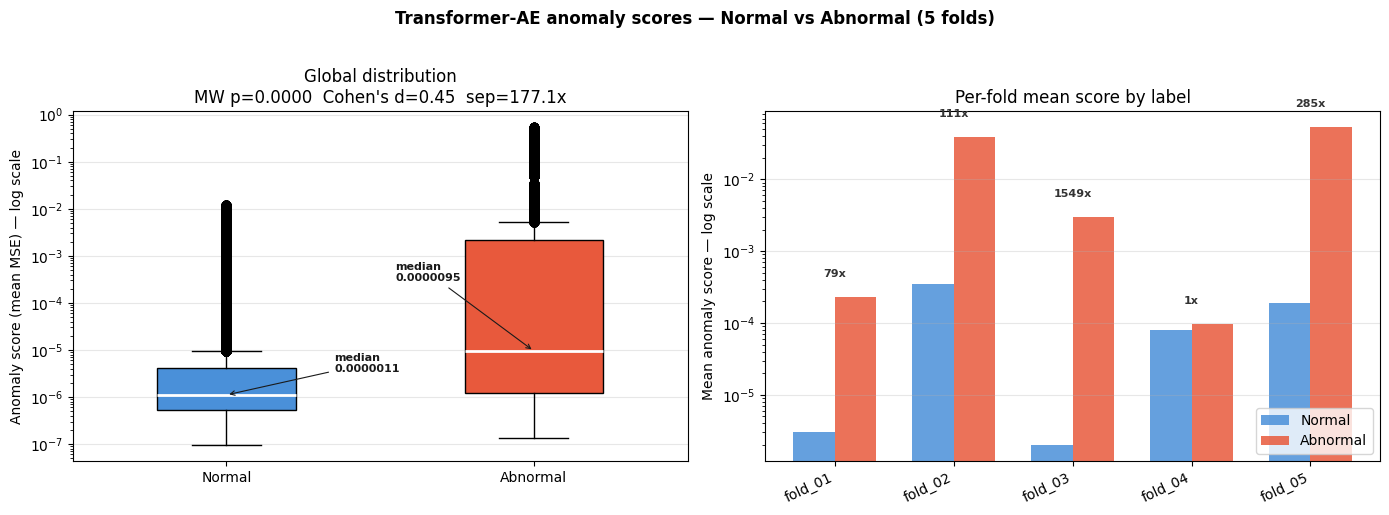

Saved.


<Figure size 640x480 with 0 Axes>

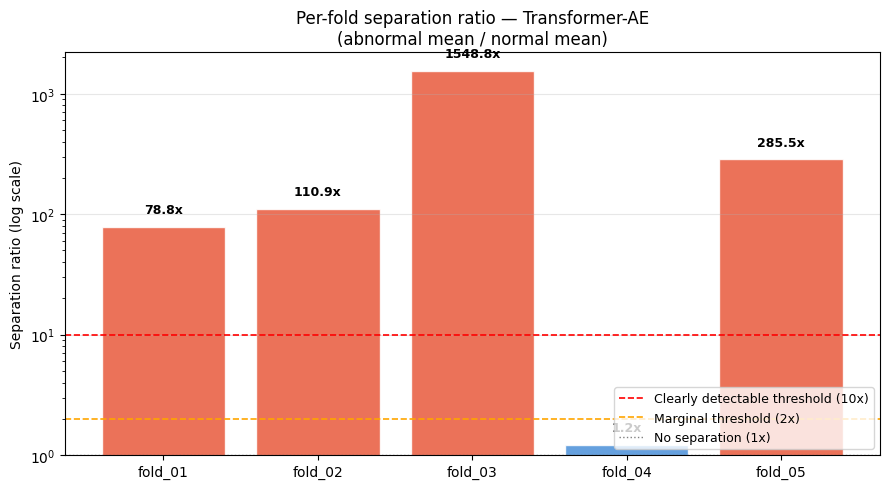

Saved.


<Figure size 640x480 with 0 Axes>

In [38]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# log-scale boxplot
bp = axes[0].boxplot(
    [normal, abnormal], tick_labels=['Normal', 'Abnormal'],
    patch_artist=True, notch=False, widths=0.45
)
bp['boxes'][0].set_facecolor('#4A90D9')
bp['boxes'][1].set_facecolor('#E8593C')
for median in bp['medians']:
    median.set_color('white')
    median.set_linewidth(2)

axes[0].set_yscale('log')
axes[0].set_ylabel('Anomaly score (mean MSE) — log scale')
axes[0].set_title(f'Global distribution\nMW p={p_val:.4f}  Cohen\'s d={d:.2f}  sep={sep_ratio:.1f}x')
axes[0].grid(True, alpha=0.3, axis='y')

# median labels
norm_med = np.median(normal)
abn_med  = np.median(abnormal)

axes[0].annotate(f'median\n{norm_med:.7f}',
                 xy=(1, norm_med), xytext=(1.35, norm_med * 3),
                 fontsize=8, fontweight='bold', color='#1a1a1a',
                 arrowprops=dict(arrowstyle='->', color='#1a1a1a', lw=0.8))

axes[0].annotate(f'median\n{abn_med:.7f}',
                 xy=(2, abn_med), xytext=(1.55, abn_med * 30),
                 fontsize=8, fontweight='bold', color='#1a1a1a',
                 arrowprops=dict(arrowstyle='->', color='#1a1a1a', lw=0.8))

# log-scale per-fold grouped bar
x       = np.arange(len(FOLDS))
w       = 0.35
n_means = df_fold_summary['Normal mean'].values
a_means = df_fold_summary['Abnormal mean'].values
sep     = df_fold_summary['Sep ratio'].values

axes[1].bar(x - w/2, n_means, w, label='Normal',   color='#4A90D9', alpha=0.85)
axes[1].bar(x + w/2, a_means, w, label='Abnormal', color='#E8593C', alpha=0.85)
axes[1].set_yscale('log')
axes[1].set_xticks(x)
axes[1].set_xticklabels(FOLDS, rotation=25, ha='right')
axes[1].set_ylabel('Mean anomaly score — log scale')
axes[1].set_title('Per-fold mean score by label')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3, axis='y')

# sep ratio inside plot area
for i, (nm, am, s) in enumerate(zip(n_means, a_means, sep)):
    top = max(nm, am) * 1.8
    axes[1].text(i, top, f'{s:.0f}x',
                 ha='center', va='bottom', fontsize=8,
                 fontweight='bold', color='#333333')

plt.suptitle('Transformer-AE anomaly scores — Normal vs Abnormal (5 folds)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
plt.savefig(OUT_DIR / 'anomaly_score_distribution.png', dpi=150, bbox_inches='tight')
print('Saved.')
#per-fold sep ratio bar
fig, ax = plt.subplots(figsize=(9, 5))

sep_vals = df_fold_summary['Sep ratio'].values
colors   = ['#E8593C' if s >= 10 else '#F5A623' if s >= 2 else '#4A90D9'
            for s in sep_vals]

ax.bar(FOLDS, sep_vals, color=colors, alpha=0.85, edgecolor='white')
ax.set_yscale('log')
ax.axhline(10, color='red',    linestyle='--', linewidth=1.2,
           label='Clearly detectable threshold (10x)')
ax.axhline(2,  color='orange', linestyle='--', linewidth=1.2,
           label='Marginal threshold (2x)')
ax.axhline(1,  color='gray',   linestyle=':',  linewidth=1.0,
           label='No separation (1x)')

for i, s in enumerate(sep_vals):
    ax.text(i, s * 1.3, f'{s:.1f}x', ha='center', fontsize=9, fontweight='bold')

ax.set_ylabel('Separation ratio (log scale)')
ax.set_title('Per-fold separation ratio — Transformer-AE\n'
             '(abnormal mean / normal mean)')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(bottom=1)

plt.tight_layout()
plt.show()
plt.savefig(OUT_DIR / 'separation_ratio_per_fold.png', dpi=150, bbox_inches='tight')
print('Saved.')

In [39]:
# inspect raw score distribution before aggregation
state = torch.load(AE_DIR / 'transformer_ae_fold_01.pt', map_location='cpu')

# load fold_01 and score a few flights manually
fold_dir = OUTPUT_ROOT / 'fold_01'
suffix   = 'v5_voltage_kfold5_fold_01'
df_test  = pd.read_parquet(fold_dir / f'test_no_dr_scaled_{suffix}.parquet')

with open(fold_dir / 'feature_cols_fold_01.json') as f:
    feature_cols = json.load(f)

model = TransformerAutoencoder(n_features=16).to(DEVICE)
model.load_state_dict(torch.load(AE_DIR / 'transformer_ae_fold_01.pt', map_location=DEVICE))
model.eval()

# score first 5 flights and print raw MSE
for fid, grp in list(df_test.groupby('log_id'))[:5]:
    X = grp[feature_cols].values.astype(np.float32)
    windows = []
    for start in range(0, len(X) - 100 + 1, 10):
        windows.append(X[start:start+100])
    wt = torch.tensor(np.stack(windows)).to(DEVICE)
    with torch.no_grad():
        recon = model(wt)
    mse = ((wt - recon)**2).mean(dim=(1,2)).cpu().numpy()
    label = grp['dataset_label'].iloc[0]
    print(f'{fid[:8]} | {label:8s} | mean_mse={mse.mean():.8f} | min={mse.min():.8f} | max={mse.max():.8f}')

022107fb | normal   | mean_mse=0.00000028 | min=0.00000020 | max=0.00000070
0d64166c | normal   | mean_mse=0.00000031 | min=0.00000020 | max=0.00000218
13efd310 | abnormal | mean_mse=0.00001269 | min=0.00000307 | max=0.00006246
14332f0c | normal   | mean_mse=0.00000024 | min=0.00000016 | max=0.00000091
160089e9 | normal   | mean_mse=0.00000045 | min=0.00000032 | max=0.00000088


In [40]:
# quick sanity — manually compute flight scores same way as above
# and compare to what score_split returned

fold_dir = OUTPUT_ROOT / 'fold_01'
suffix   = 'v5_voltage_kfold5_fold_01'
df_test  = pd.read_parquet(fold_dir / f'test_no_dr_scaled_{suffix}.parquet')

with open(fold_dir / 'feature_cols_fold_01.json') as f:
    feature_cols = json.load(f)

manual_scores = {}
for fid, grp in df_test.groupby('log_id'):
    X = grp[feature_cols].values.astype(np.float32)
    windows = []
    for start in range(0, len(X) - 100 + 1, 10):
        windows.append(X[start:start+100])
    wt = torch.tensor(np.stack(windows)).to(DEVICE)
    with torch.no_grad():
        recon = model(wt)
    mse = ((wt - recon)**2).mean(dim=(1,2)).cpu().numpy()
    label = grp['dataset_label'].iloc[0]
    manual_scores[fid] = {'score': mse.mean(), 'label': label}

manual_df = pd.DataFrame(manual_scores).T.reset_index()
manual_df.columns = ['log_id', 'score', 'label']
manual_df['score'] = manual_df['score'].astype(float)

print('Normal mean  :', manual_df[manual_df['label']=='normal']['score'].mean())
print('Abnormal mean:', manual_df[manual_df['label']=='abnormal']['score'].mean())
print('\nPer flight:')
print(manual_df.sort_values('score', ascending=False)[['log_id','label','score']].to_string(index=False))

Normal mean  : 3.0792835516990635e-06
Abnormal mean: 0.000312636609120176

Per flight:
                              log_id    label        score
a3363780-8647-4341-a38a-77176235cdf2 abnormal 2.149147e-03
25c37f03-8611-4026-bb3a-ae908b19fb71 abnormal 3.192870e-04
83b00da7-f696-4af4-b3b7-f768fead3c7f   normal 4.094708e-05
670aaff6-ba17-4047-ae2c-53e26d74bf74   normal 1.790309e-05
d2dc82d7-0024-4562-b8dc-2edf5e4bbf22 abnormal 1.577289e-05
13efd310-a978-497d-8360-cc5b7b4a7d1a abnormal 1.269369e-05
e4c9925e-ebc8-4e02-aab3-da50ed1f8891   normal 3.011580e-06
d5fdc214-a392-42a1-9339-bb804e8f6af2   normal 2.421953e-06
25b9904e-0cf3-4ec7-aa78-48ee664818e4   normal 2.196407e-06
1dffb068-95fb-427c-9b3f-eba9ab6b9052   normal 2.145113e-06
7f74d2ab-19eb-4211-9993-663a7e5f1d84   normal 2.025223e-06
cb358ec1-2de5-4ff3-97c4-4d02f939cc39 abnormal 1.975508e-06
88f7d5ba-9eda-4e38-85ef-00d869562cab   normal 1.937011e-06
d22e643a-8935-4717-a194-04cc834630fe abnormal 1.459191e-06
d6b76077-5896-4e81-a966-8e30

In [41]:
for fold in ['fold_01', 'fold_02', 'fold_03']:
    df = pd.read_parquet(ENRICHED_DIR / f'train_enriched_{fold}.parquet')
    pct_zero = (df['anomaly_score'] == 0).mean()
    print(f'{fold} | zeros={pct_zero:.1%} | '
          f'min={df["anomaly_score"].min():.4f} | '
          f'max={df["anomaly_score"].max():.4f} | '
          f'mean={df["anomaly_score"].mean():.4f}')

fold_01 | zeros=0.0% | min=0.0000 | max=1.0000 | mean=0.0252
fold_02 | zeros=0.0% | min=0.0000 | max=1.0000 | mean=0.0948
fold_03 | zeros=0.0% | min=0.0000 | max=1.0000 | mean=0.0518
